# Локализация и семейство R-CNN
Лабораторная работа 11. Сначала проверим относительное кодирование рамок, NMS и два варианта AP. Затем сравним стоимость трёх вычислительных ветвей. Нужны PyTorch, Pillow и IPython, а также папки Chapter_10 и Chapter_11 с кодом. Загружать данные и веса не требуется.

In [1]:
from pathlib import Path
import sys
import torch

roots = (Path.cwd(), *Path.cwd().parents)
book = next((p for root in roots for p in (root, root / "Deep_Learning_Textbook")
             if (p / "Python_Code").is_dir()), None)
assert book is not None, "Откройте notebook из папки учебника"

import math
sys.path.insert(0, str(book / "Python_Code" / "Chapter_11"))
from localization_rcnn import average_precision, decode_boxes, encode_boxes, greedy_nms, main

## Рамочная регрессия и оценка качества
Опора [10,20,30,40] имеет центр (20,30), размер (20,20). Эталон [14,17,38,47] имеет центр (26,32), размер (24,30). Проверим вектор (0,3; 0,1; ln 1,2; ln 1,5). Для рангов TP, FP, TP при двух эталонах AP площади равна 5/6, VOC07 — 28/33.

In [2]:
anchor = torch.tensor([[10.,20.,30.,40.]], dtype=torch.float64)
target = torch.tensor([[14.,17.,38.,47.]], dtype=torch.float64)
delta = encode_boxes(anchor, target)
expected = torch.tensor([[.3,.1,math.log(1.2),math.log(1.5)]], dtype=torch.float64)
torch.testing.assert_close(delta, expected)
torch.testing.assert_close(decode_boxes(anchor, delta), target)
ap = average_precision([True, False, True], 2)
assert math.isclose(ap["ap_area"], 5/6) and math.isclose(ap["ap_voc07"], 28/33)
print("Дельты:", delta.tolist(), "Два AP:", ap["ap_area"], ap["ap_voc07"])

Дельты: [[0.3, 0.1, 0.1823215567939546, 0.4054651081081644]] Два AP: 0.8333333333333333 0.8484848484848485


## Измерение вычислительных ветвей
Короткий профиль: 6 регионов, 9 повторов и один внутриоперационный поток. Скрипт использует случайные веса и изображение. Он проверяет работу с регионами и измеряет время, а качество исторических детекторов рассматривается отдельно по статьям.

In [3]:
report = main(["--profile", "short", "--seed", "42"])
assert report["proposals"] == 6
assert report["numerical"]["per_class"] == [0, 2, 3]
assert report["numerical"]["agnostic"] == [0, 2]
routes = report["routes"]
assert [row["backbone_passes"] for row in routes.values()] == [6,1,1]
assert all(0 < row["p50_ms"] <= row["p95_ms"] for row in routes.values())

profile=short torch=2.10.0+cpu seed=42 regions=6 repeats=9 CPU_threads_for_timing=1
delta = [0.3, 0.1, 0.182322, 0.405465] decoded = [14.0, 17.0, 38.0, 47.0]
IoU(A,B)=0.680672 NMS classwise=[0, 2, 3] class-agnostic=[0, 2]
AP integral=0.833333 AP VOC07=0.848485
crop_first: passes=6 sites=24576 p50_ms=8.366 p95_ms=10.587
shared_external: passes=1 sites=16384 p50_ms=3.166 p95_ms=3.542
shared_score: passes=1 sites=16384 p50_ms=3.692 p95_ms=4.479


## Сравнение времени
Полосы показывают p50 и p95 каждого пути в миллисекундах. Время относится к данному CPU-сеансу. Сравните результаты при 1, 4, 8 и 16 регионах; число проходов само по себе не определяет p95.

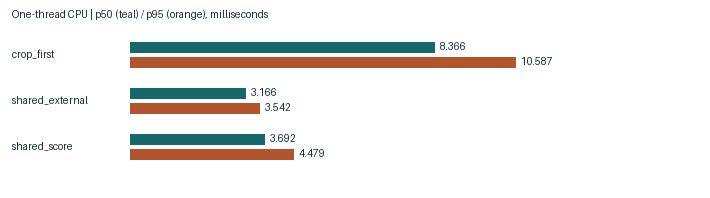

In [4]:
from io import BytesIO
from PIL import Image, ImageDraw
from IPython.display import Image as DisplayImage, display

canvas = Image.new("RGB", (710, 198), "white")
draw = ImageDraw.Draw(canvas)
draw.text((12,8), "One-thread CPU | p50 (teal) / p95 (orange), milliseconds", fill="#162f37")
scale = 385 / max(row["p95_ms"] for row in routes.values())
for i, (name, values) in enumerate(routes.items()):
    y = 42 + 46*i
    draw.text((12,y+6), name, fill="#162f37")
    for j, (key, color) in enumerate((("p50_ms","#17686b"), ("p95_ms","#b0552c"))):
        value = values[key]
        end = 130+round(value*scale)
        draw.rectangle((130,y+15*j,end,y+15*j+10),fill=color)
        draw.text((end+6,y+15*j-2),f"{value:.3f}",fill="#162f37")
buffer = BytesIO()
canvas.save(buffer, format="PNG")
display(DisplayImage(data=buffer.getvalue()))

## Задания
A. Повторите NMS с порогом 0,7 и объясните различия. B. Постройте зависимость p50/p95 от количества регионов. C. Спроектируйте отдельное сравнение обученных детекторов с общей метрикой AP и двумя явно ограниченными таймерами.